# Does excluding low-extent GFTM modes fix KBM mode selection?

Fusion_PhD-38e9.1. On the KBM Latin hypercubes most GFTM error is mode **selection**, not
identification: a mode close to GS2 is in GFTM's 4-mode spectrum but is not the fastest one.
Hypothesis: spurious fast modes with a short ballooning-angle **extent** win the argmax.

Data: the WIDTH-oracle scan (`wo_*` leaves; `docs/gyro_data_runs.md` in Fusion_PhD), GFTM at fixed
NBASIS_MAX=22 / NXGRID=28, FILTER=0.0, NMODES=4, 24 fixed widths 0.2-4.0, on SPR-045 (`KB_MODELS`)
and M1 (`KB_MODELS_MAST`). GS2 reference: the tail-averaged `pyro_cube_avg` bundles.
Extent: `pyrokinetics.diagnostics.extent.Extent` (branch `feature/extent_diagnostic`, 95% rule),
applied to each cube's `eigenfunctions`.

Sections: (a) the premise measured, (b) extent of spurious vs oracle modes, (c) the cutoff sweep,
plus three checks on the extent numbers. (d), the tearing-parity baseline, is DEFERRED to pyro#594:
FieldLine.compute_linear_tearing_parameter cannot read these GFTM cubes, and parity is not reimplemented here.

**The oracle (mode closest to GS2) consults the answer: it is a bound, never an accuracy.**

## Imports and settings

In [1]:
from pathlib import Path
import os
import warnings
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import pyrokinetics
from pyrokinetics import Pyro
from pyrokinetics.pyroscan import PyroScanGKOutput
from pyrokinetics.dataset_wrapper import DatasetWrapper
from pyrokinetics.diagnostics.extent import Extent
from pyrokinetics.diagnostics.field_line import FieldLine

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir()
)
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
load_dotenv(ROOT / "local.env", override=True)
print("pyrokinetics", pyrokinetics.__version__)

analysis_name = "kbm_extent_filter"
data_root = Path(os.environ["GK_DATA_ROOT"]).expanduser()
run_template = "Runs"
project = "LATIN_HYPERCUBE"
cases = {"SPR-045": "SPR-045", "M1": "M1"}  # database label -> case directory
scan_information = {"GFTM": "kbm_8d/wo_{width}", "GS2": "kbm_8d"}
output_dir = {"GFTM": "pyro_cube", "GS2": "pyro_cube_avg"}  # GS2: tail-averaged reference
output_file = "cube.nc"
gs2_input_file = "gs2.in"   # per-run GS2 input (scan dir / sample name / this); pyro reads gs2.out.nc beside it
widths = ["w0p2000", "w0p2297", "w0p2639", "w0p3031", "w0p3482", "w0p4000", "w0p4595",
          "w0p5279", "w0p6063", "w0p6965", "w0p8000", "w0p9000", "w1p0000", "w1p1000",
          "w1p2000", "w1p3000", "w1p4000", "w1p5000", "w1p6000", "w1p9218", "w2p3083",
          "w2p7726", "w3p3302", "w4p0000"]
width_value = {w: float(w[1:].replace("p", ".")) for w in widths}
expected_resolution = {"nbasis_used": 22, "nxgrid_used": 28}

fraction = 0.95                             # Extent's rule: theta range holding 95% of |Re field|^2
fields = ["phi", "apar"]                    # phi selects; apar reported alongside
cutoffs = np.round(np.arange(0, 12.01, 0.25), 2)       # absolute extent cutoff [rad]
rel_cutoffs = np.round(np.arange(0, 1.001, 0.05), 2)   # fraction of the case's largest unstable-mode extent
edge_amplitude = 0.05    # check 1: |phi| at the theta-grid edge above this fraction of its peak
delta_lim = 0.2          # fig 2 colour range for the medlog change (clipped; misses-dominate cells are grey)
example_width = "w1p0000"
n_examples = 3

pyrokinetics 0.9.2.dev30+gfa3864e7


## Load data

One `PyroScanGKOutput` per (database, width), read from the cube's netCDF. The extent branch has no
`PyroHypercube` or GFTM reader, so the cube is loaded as the scan's gk_output object, which carries
units. `Extent` adds `extent(sample, field, mode)` and `bounds(..., bound=lo/hi)` in place.

In [2]:
gs2, gftm = {}, {}
for db, case in cases.items():
    gs2[db] = PyroScanGKOutput.from_netcdf(
        data_root / "GS2" / run_template / project / case / scan_information["GS2"] / output_dir["GS2"] / output_file)
    Extent(gs2[db], fraction=fraction)   # GS2 extents: used by the GFTM-vs-GS2 extent comparison at the end
    for w in widths:
        out = PyroScanGKOutput.from_netcdf(
            data_root / "GFTM" / run_template / project / case / scan_information["GFTM"].format(width=w)
            / output_dir["GFTM"] / output_file)
        Extent(out, fraction=fraction)
        gftm[db, w] = out
    print(db, "GS2 samples", gs2[db].data.sizes["sample"], "| GFTM cubes", len(widths))

SPR-045 GS2 samples 300 | GFTM cubes 24
M1 GS2 samples 300 | GFTM cubes 24


## Calculate and select

Conventions, checked rather than assumed: both codes' growth rates are in the same pyrokinetics
units; each cube's audited resolution (`*_used`, from `out.gftm.localdump`) is the requested one.

Per case, GFTM returns 4 modes. A **selector** takes the argmax growth rate over `mode` among
*unstable* modes (gamma > 0) that pass its gate. A case where no unstable mode passes is a **MISS**:
it stays in the population with gamma_sel = 0, so its |log10| error is +inf and its absolute error is
gamma_GS2. Misses therefore move the median, and medlog becomes inf once they are the majority.

Population: cases whose GS2 growth rate is finite and positive (the same cases for every selector
and width, so every comparison is paired).

- `dominant`: no gate (c = 0; the current argmax over unstable modes).
- `oracle`: the unstable mode with the smallest |log10(gamma/gamma_GS2)| -- a bound.
- `extent >= c`: absolute cutoff on the 95% extent of phi (apar alongside).
- `extent >= r * max extent`: relative cutoff on the case's own longest unstable mode.

In [3]:
def mag(v):
    return np.asarray(getattr(v.data, "magnitude", v.data))


def select(gam, keep):
    # argmax growth over 'mode' among unstable modes passing `keep`; 0 where none passes (a MISS)
    g = np.where(keep & (gam > 0), gam, -np.inf)
    idx = g.argmax(axis=1)
    return np.where(np.isfinite(g.max(axis=1)), gam[np.arange(len(gam)), idx], 0.0), idx


def score(g_sel, g_ref):
    with np.errstate(divide="ignore"):
        log_err = np.abs(np.log10(g_sel / g_ref))
    return np.median(np.abs(g_sel - g_ref)), np.median(log_err), int((g_sel == 0).sum())


rows, sweep, cases_data = [], [], {}
for (db, w), out in gftm.items():
    d, ref = out.data, gs2[db].data
    assert str(d.growth_rate.data.units) == str(ref.growth_rate.data.units), "normalisations differ"
    for var, value in expected_resolution.items():
        assert (mag(d[var]) == value).all(), f"{db}/{w}: {var} is not {value}"
    assert np.allclose(mag(d.width_used), width_value[w])

    ref_by_name = dict(zip(ref.sample_name.values, mag(ref.growth_rate)))
    g_ref_all = np.array([ref_by_name.get(n, np.nan) for n in d.sample_name.values])
    ok = np.isfinite(g_ref_all) & (g_ref_all > 0)
    g_ref = g_ref_all[ok]
    gam = mag(d.growth_rate.transpose("sample", "mode"))[ok]
    ext = {f: mag(d.extent.sel(field=f).transpose("sample", "mode"))[ok] for f in fields}
    theta = d.theta.values
    phi = mag(d.eigenfunctions.sel(field="phi").transpose("sample", "theta", "mode"))[ok]

    unstable = gam > 0
    g_dom, i_dom = select(gam, True)
    with np.errstate(divide="ignore", invalid="ignore"):
        dist = np.where(unstable, np.abs(np.log10(gam / g_ref[:, None])), np.inf)
    i_orc = dist.argmin(axis=1)
    g_orc = np.where(unstable.any(axis=1), gam[np.arange(len(gam)), i_orc], 0.0)

    # check 1: 95% bounds within one grid spacing of the edge, or |phi| at the edge above edge_amplitude of peak
    lo, hi = (mag(d.bounds.sel(field="phi", bound=b).transpose("sample", "mode"))[ok] for b in ("lo", "hi"))
    dtheta = theta[1] - theta[0]
    at_edge = (lo <= theta[0] + dtheta) | (hi >= theta[-1] - dtheta)
    edge_amp = np.maximum(np.abs(phi[:, 0]), np.abs(phi[:, -1])) / np.abs(phi).max(axis=1)

    # check 2: rotate each eigenfunction so its peak is real, recompute Extent
    e = mag(d.eigenfunctions)
    axis = d.eigenfunctions.get_axis_num("theta")
    peak = np.take_along_axis(e, np.abs(e).argmax(axis=axis, keepdims=True), axis=axis)
    rot = DatasetWrapper(data_vars={"eigenfunctions": d.eigenfunctions.copy(data=e * np.exp(-1j * np.angle(peak)))})
    Extent(rot, fraction=fraction)
    with np.errstate(divide="ignore", invalid="ignore"):
        phase_change = {f: np.abs(mag(rot.data.extent.sel(field=f).transpose("sample", "mode"))[ok] - ext[f]) / ext[f]
                        for f in fields}
    del rot

    differ = i_dom != i_orc
    with np.errstate(divide="ignore"):
        err_dom, err_orc = np.abs(np.log10(g_dom / g_ref)), np.abs(np.log10(g_orc / g_ref))
    r = np.arange(len(gam))
    row = dict(db=db, width=width_value[w], n=int(ok.sum()), n_gs2_stable_or_nan=int((~ok).sum()),
               differ=int(differ.sum()),
               medlog_dom=score(g_dom, g_ref)[1], medlog_orc=score(g_orc, g_ref)[1],
               medAE_dom=score(g_dom, g_ref)[0], medAE_orc=score(g_orc, g_ref)[0],
               medlog_dom_agree=np.median(err_dom[~differ]), medlog_dom_differ=np.median(err_dom[differ]),
               medlog_orc_differ=np.median(err_orc[differ]),
               share_err_from_differ=err_dom[differ & np.isfinite(err_dom)].sum() / err_dom[np.isfinite(err_dom)].sum(),
               unstable_modes=int(unstable.sum()), unstable_nan_extent=int((unstable & ~np.isfinite(ext["phi"])).sum()),
               frac_bounds_at_edge=at_edge[unstable].mean(), frac_edge_amp=(edge_amp[unstable] > edge_amplitude).mean(),
               **{f"phase_{f}_median_rel_change": np.nanmedian(phase_change[f][unstable]) for f in fields},
               **{f"phase_{f}_frac_over_10pct": (phase_change[f][unstable] > 0.1).mean() for f in fields})
    for f in fields:
        a, b = ext[f][r, i_dom][differ], ext[f][r, i_orc][differ]
        row[f"{f}_ext_dom_shorter"] = (a < b).mean()
        row[f"{f}_ext_ratio_median"] = np.median(a / b)
    rows.append(row)

    longest = np.nanmax(np.where(unstable, ext["phi"], np.nan), axis=1, initial=0)
    for f in fields:
        for kind, grid in (("abs", cutoffs), ("rel", rel_cutoffs)):
            for c in grid:
                threshold = c if kind == "abs" else c * longest[:, None]
                keep = (ext[f] >= threshold) | (c == 0)   # c = 0 keeps NaN-extent modes: exactly `dominant`
                medAE, medlog, miss = score(select(gam, keep)[0], g_ref)
                sweep.append(dict(db=db, width=width_value[w], field=f, kind=kind, cutoff=c,
                                  medlog=medlog, medAE=medAE, miss=miss, n=len(g_ref)))
    cases_data[db, w] = dict(names=d.sample_name.values[ok], gam=gam, g_ref=g_ref, i_dom=i_dom, i_orc=i_orc,
                             ext=ext, err_dom=err_dom, differ=differ)

summary = pd.DataFrame(rows)
sweep = pd.DataFrame(sweep)

## Extended KBMs: interpretation

**Revised by the next section:** the extended GS2 modes (>= 12 rad) turn out to be mostly microtearing-like on M1 and
unconverged near-marginal runs on SPR-045, not well-resolved KBMs. The measurements below stand; read "extended
KBMs" as "extended GS2 modes".

- **In the unbiased WIDTH band (0.45-1.6), GFTM does not reproduce the extended GS2 modes.** For compact GS2 modes
  (phi extent < 6 rad, 392 of 452 cases) GFTM's extent matches (median log2 ratio -0.08 to +0.09, almost never >x2
  short). For the most extended GS2 modes (12-31 rad; 13 SPR-045 and 31 M1 cases) GFTM's dominant mode is 3-6x too
  compact (GS2 median 20-28 rad vs GFTM 3-6 rad; 68-88% more than 2x short), and the 6-12 rad bin (7 + 9 cases) is
  ~1.4x short. FILTER=0.5 does not help here (slightly shorter still).
- **Those cases carry large errors.** Growth medlog 0.45-0.56 (vs 0.05-0.21 for compact modes) and, on M1, frequency
  errors ~1.0-1.1 (vs 0.04-0.07): GFTM is finding a different, compact mode, not a poorly resolved version of GS2's.
- **A larger WIDTH does not rescue them.** GFTM's extent for these cases only approaches GS2's at WIDTH >= 2-3 (fig 13,
  top), but the growth error there is no better, often worse (best growth WIDTH for the 12-31 rad bin is 0.26-0.46).
  Frequency improves at WIDTH 4 on M1 (0.41 vs 0.81 in band) but stays far above the compact-mode error.
- Caveats: small bins (7-31 cases per database). GS2 extents in the top bin are lower bounds (+-5 pi grid).

# Are the extended GS2 modes resolved, and are they KBMs?

The extended bin is small, so each GS2 eigenfunction with phi extent >= `extended_threshold` is plotted (|phi| and
|apar|, each normalised to its own peak, log scale so the tails at the grid edge are visible). Diagnostics, compared
with the compact GS2-unstable cases:

- **Box length**: peak |field| within `edge_window` of the theta-grid edge, relative to the field's peak. A mode that
  has not decayed at the edge is truncated by GS2's ballooning box (and its extent is a lower bound).
- **Convergence**: GS2's `growth_rate_tolerance`.
- **KBM signature**: ballooning parity (phi even, apar odd: even-part fraction of the power, using theta -> -theta on
  GS2's symmetric grid), max|apar|/max|phi| in pyro's normalisation, the apar share of the heat flux (summed over
  species), and the frequency sign against the compact population (pyro's sign convention, same for both groups).

## Extended GS2 modes: calculate

In [44]:
extended_threshold = 12.0   # rad: GS2 phi extent defining an extended mode (top bin of gs2_extent_bins)
edge_window = 1.0           # rad: 'edge' = |theta| within this of the grid end
edge_max = 0.1              # |phi| at the edge above this fraction of its peak: not decayed inside GS2's box
gamma_tol_max = 0.1         # GS2 growth_rate_tolerance above this: treated as not converged (compact medians 0.00-0.02)

rows_gs2 = []
for db in cases:
    ref = gs2[db].data
    theta = ref.theta.values
    assert np.allclose(theta, -theta[::-1]), f"{db}: GS2 theta grid not symmetric, parity check invalid"
    field_index = {f: list(ref.field.values).index(f) for f in ("phi", "apar")}
    ef = mag(ref.eigenfunctions.transpose("sample", "field", "theta"))
    heat = mag(ref.heat.sum("species").transpose("sample", "field"))
    edge = np.abs(theta) >= np.abs(theta).max() - edge_window
    for s in np.where(np.isin(ref.sample_name.values, cases_data[db, widths[0]]["names"]))[0]:   # GS2-unstable cases
        row = dict(db=db, name=ref.sample_name.values[s], gamma=float(mag(ref.growth_rate)[s]),
                   omega=float(mag(ref.mode_frequency)[s]), gamma_tol=float(mag(ref.growth_rate_tolerance)[s]),
                   beta=float(ref.beta.values[s]), shat=float(ref.shat.values[s]), q=float(ref.q.values[s]))
        with np.errstate(invalid="ignore"):   # the 20 SPR-045 cases without GS2 eigenfunctions give NaN here
            row["em_heat_frac"] = heat[s, field_index["apar"]] / heat[s].sum()
            for f in ("phi", "apar"):
                e = ef[s, field_index[f]]
                even, odd = e + e[::-1], e - e[::-1]
                row[f"ext_{f}"] = float(mag(ref.extent.sel(field=f))[s])
                row[f"edge_{f}"] = np.abs(e[edge]).max() / np.abs(e).max()
                row[f"even_frac_{f}"] = np.sum(np.abs(even) ** 2) / (np.sum(np.abs(even) ** 2) + np.sum(np.abs(odd) ** 2))
            row["apar_over_phi"] = np.abs(ef[s, field_index["apar"]]).max() / np.abs(ef[s, field_index["phi"]]).max()
        rows_gs2.append(row)
gs2_diag = pd.DataFrame(rows_gs2)
gs2_diag = gs2_diag.assign(
    group=np.where(gs2_diag.ext_phi >= extended_threshold, "extended", np.where(np.isfinite(gs2_diag.ext_phi), "compact", "no extent")),
    parity=np.where(gs2_diag.even_frac_phi > 0.5, "twisting (phi even)", "tearing (phi odd)"),
    converged=gs2_diag.gamma_tol <= gamma_tol_max, decayed=gs2_diag.edge_phi <= edge_max)

cols = ["gamma", "omega", "gamma_tol", "edge_phi", "edge_apar", "even_frac_phi", "even_frac_apar", "apar_over_phi",
        "em_heat_frac", "beta", "shat", "q"]
print("--- medians by group (GS2-unstable cases) ---")
print(gs2_diag.groupby(["db", "group"])[cols].median().assign(n=gs2_diag.groupby(["db", "group"]).size()).round(3).to_string())
print("\n--- fraction with omega < 0, by group ---")
print(gs2_diag.groupby(["db", "group"]).omega.apply(lambda x: (x < 0).mean()).round(2).to_string())
has_ef = gs2_diag.group != "no extent"
print("\n--- parity / converged / decayed within the box: counts by group ---")
print(pd.crosstab([gs2_diag[has_ef].db, gs2_diag[has_ef].group],
                  [gs2_diag[has_ef].parity, gs2_diag[has_ef].converged.map({True: "converged", False: "not converged"}),
                   gs2_diag[has_ef].decayed.map({True: "decayed", False: "at box edge"})]).to_string())
print("\n--- extended cases ---")
print(gs2_diag[gs2_diag.group == "extended"].sort_values(["db", "ext_phi"])[["db", "name", "parity", "ext_phi", "ext_apar"] + cols]
      .round(3).to_string(index=False))

/pitagora_work/FUPB2_QLTURB/fwatts/General_Analysis_kbm_extent/.venv/lib/python3.14/site-packages/xarray/core/variable.py:363: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)
/pitagora_work/FUPB2_QLTURB/fwatts/General_Analysis_kbm_extent/.venv/lib/python3.14/site-packages/xarray/core/variable.py:363: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


--- medians by group (GS2-unstable cases) ---
                   gamma  omega  gamma_tol  edge_phi  edge_apar  even_frac_phi  even_frac_apar  apar_over_phi  em_heat_frac   beta   shat      q    n
db      group                                                                                                                                        
M1      compact    0.204  0.301      0.000     0.008      0.000            1.0             0.0          0.136        -0.061  0.026  2.719  3.255  221
        extended   0.030 -0.615      0.003     0.490      0.058            0.0             1.0          0.870         0.985  0.050  1.057  3.654   31
SPR-045 compact    0.031  0.017      0.019     0.005      0.000            1.0             0.0          1.092        -0.066  0.043  2.563  3.282  187
        extended   0.012 -0.007      1.326     0.098      0.034            1.0             0.0          0.189        -0.045  0.026  0.190  4.309   13
        no extent  0.768  0.104      0.000       NaN  

### Pyrokinetics tearing parameter from the individual GS2 runs

`FieldLine.compute_linear_tearing_parameter` = |integral A_par dl| / integral |A_par| dl along the field line (~1 tearing
parity, ~0 twisting). It needs each run's geometry and `nperiod`, which the cube does not carry, so every GS2-unstable
case is loaded from its own run directory (`gs2.in`, with `gs2.out.nc` read alongside; final time slice). Read-only;
failures are recorded, not dropped. ~2 s per run.

In [ ]:
tearing_threshold = 0.5   # pyro tearing parameter above this: tearing parity

from general_analysis import mode_classification as mc

rows_tp = []
for db, case in cases.items():
    base = data_root / "GS2" / run_template / project / case / scan_information["GS2"]
    scan, ds = mc.load_gs2_cube(base, "pyro_cube")   # FINAL-time cube: the tail-averaged one above is not the field T is defined on
    ind = mc.indicators(scan, ds).to_dataframe().set_index("sample_name")
    num = scan.base_pyro.numerics   # nperiod/ntheta are not scanned
    for name in gs2_diag[gs2_diag.db == db].name:
        rows_tp.append(dict(db=db, name=name, tearing_parameter=ind["T"].get(name, np.nan), nperiod=num.nperiod, ntheta=num.ntheta,
                            error="" if name in ind.index else "not in the final-time cube"))
tearing = pd.DataFrame(rows_tp)
print("runs:", len(tearing), "| not in cube:", int((tearing.error != "").sum()),
      "| tearing parameter not finite:", int(((tearing.error == "") & ~np.isfinite(tearing.tearing_parameter)).sum()))
print(tearing[(tearing.error != "") | ~np.isfinite(tearing.tearing_parameter)].to_string(index=False))
print("nperiod / ntheta used:", tearing.groupby(["db", "nperiod", "ntheta"]).size().to_dict())

In [ ]:
gs2_diag = gs2_diag.drop(columns=[c for c in ("tearing_parameter", "nperiod") if c in gs2_diag]).merge(
    tearing[["db", "name", "tearing_parameter", "nperiod"]], on=["db", "name"], how="left")
gs2_diag = gs2_diag.assign(pyro_parity=np.where(gs2_diag.tearing_parameter > tearing_threshold, "tearing",
                                                np.where(gs2_diag.tearing_parameter.notna(), "twisting", "failed")))

print(f"--- pyro tearing parameter > {tearing_threshold}: counts by group ---")
print(pd.crosstab([gs2_diag.db, gs2_diag.group], gs2_diag.pyro_parity).to_string())
has_ef = (gs2_diag.group != "no extent") & gs2_diag.tearing_parameter.notna()
same = (gs2_diag.pyro_parity == np.where(gs2_diag.even_frac_phi > 0.5, "twisting", "tearing"))[has_ef]
print(f"\npyro parity agrees with the even-fraction label in {same.sum()}/{len(same)} cases with GS2 eigenfunctions")
print(gs2_diag[has_ef & ~same][["db", "name", "group", "parity", "even_frac_phi", "tearing_parameter"]].round(3).to_string(index=False))
print("\n--- tearing parameter quantiles by group ---")
print(gs2_diag.groupby(["db", "group"]).tearing_parameter.quantile([0.1, 0.5, 0.9]).unstack().round(3).to_string())
print("\n--- extended cases ---")
print(gs2_diag[gs2_diag.group == "extended"].sort_values(["db", "ext_phi"])[
    ["db", "name", "ext_phi", "parity", "tearing_parameter", "pyro_parity", "nperiod", "omega", "em_heat_frac", "converged", "decayed"]]
      .round(3).to_string(index=False))

--- pyro tearing parameter > 0.5: counts by group ---
pyro_parity        failed  tearing  twisting
db      group                               
M1      compact         0        3       218
        extended        0       22         9
SPR-045 compact         0        0       187
        extended        0        0        13
        no extent       2        0        18

pyro parity agrees with the even-fraction label in 451/452 cases with GS2 eigenfunctions
db          name    group            parity  even_frac_phi  tearing_parameter
M1 iteration_169 extended tearing (phi odd)            0.0              0.426

--- tearing parameter quantiles by group ---
                   0.1   0.5    0.9
db      group                      
M1      compact    0.0  0.00  0.000
        extended   0.0  0.79  0.880
SPR-045 compact    0.0  0.00  0.001
        extended   0.0  0.00  0.012
        no extent  0.0  0.00  0.000

--- extended cases ---
     db          name  ext_phi              parity  tearing_par

## Extended GS2 modes: plot

One figure per database; one panel per extended case, sorted by phi extent. Real (solid) and imaginary (dashed) parts
of phi and apar, each divided by its own peak |field|, after one common phase rotation that makes phi's peak real and
positive (so the phi-apar relative phase is kept). Dotted lines mark the `edge_window` at each end of GS2's theta grid.
Title: pyro tearing parameter (TP; ~1 tearing, ~0 twisting), gamma, omega, phi extent, phi/apar edge amplitude, GS2
growth-rate tolerance. Fig 15: tearing parameter vs GS2 phi extent for all GS2-unstable cases.

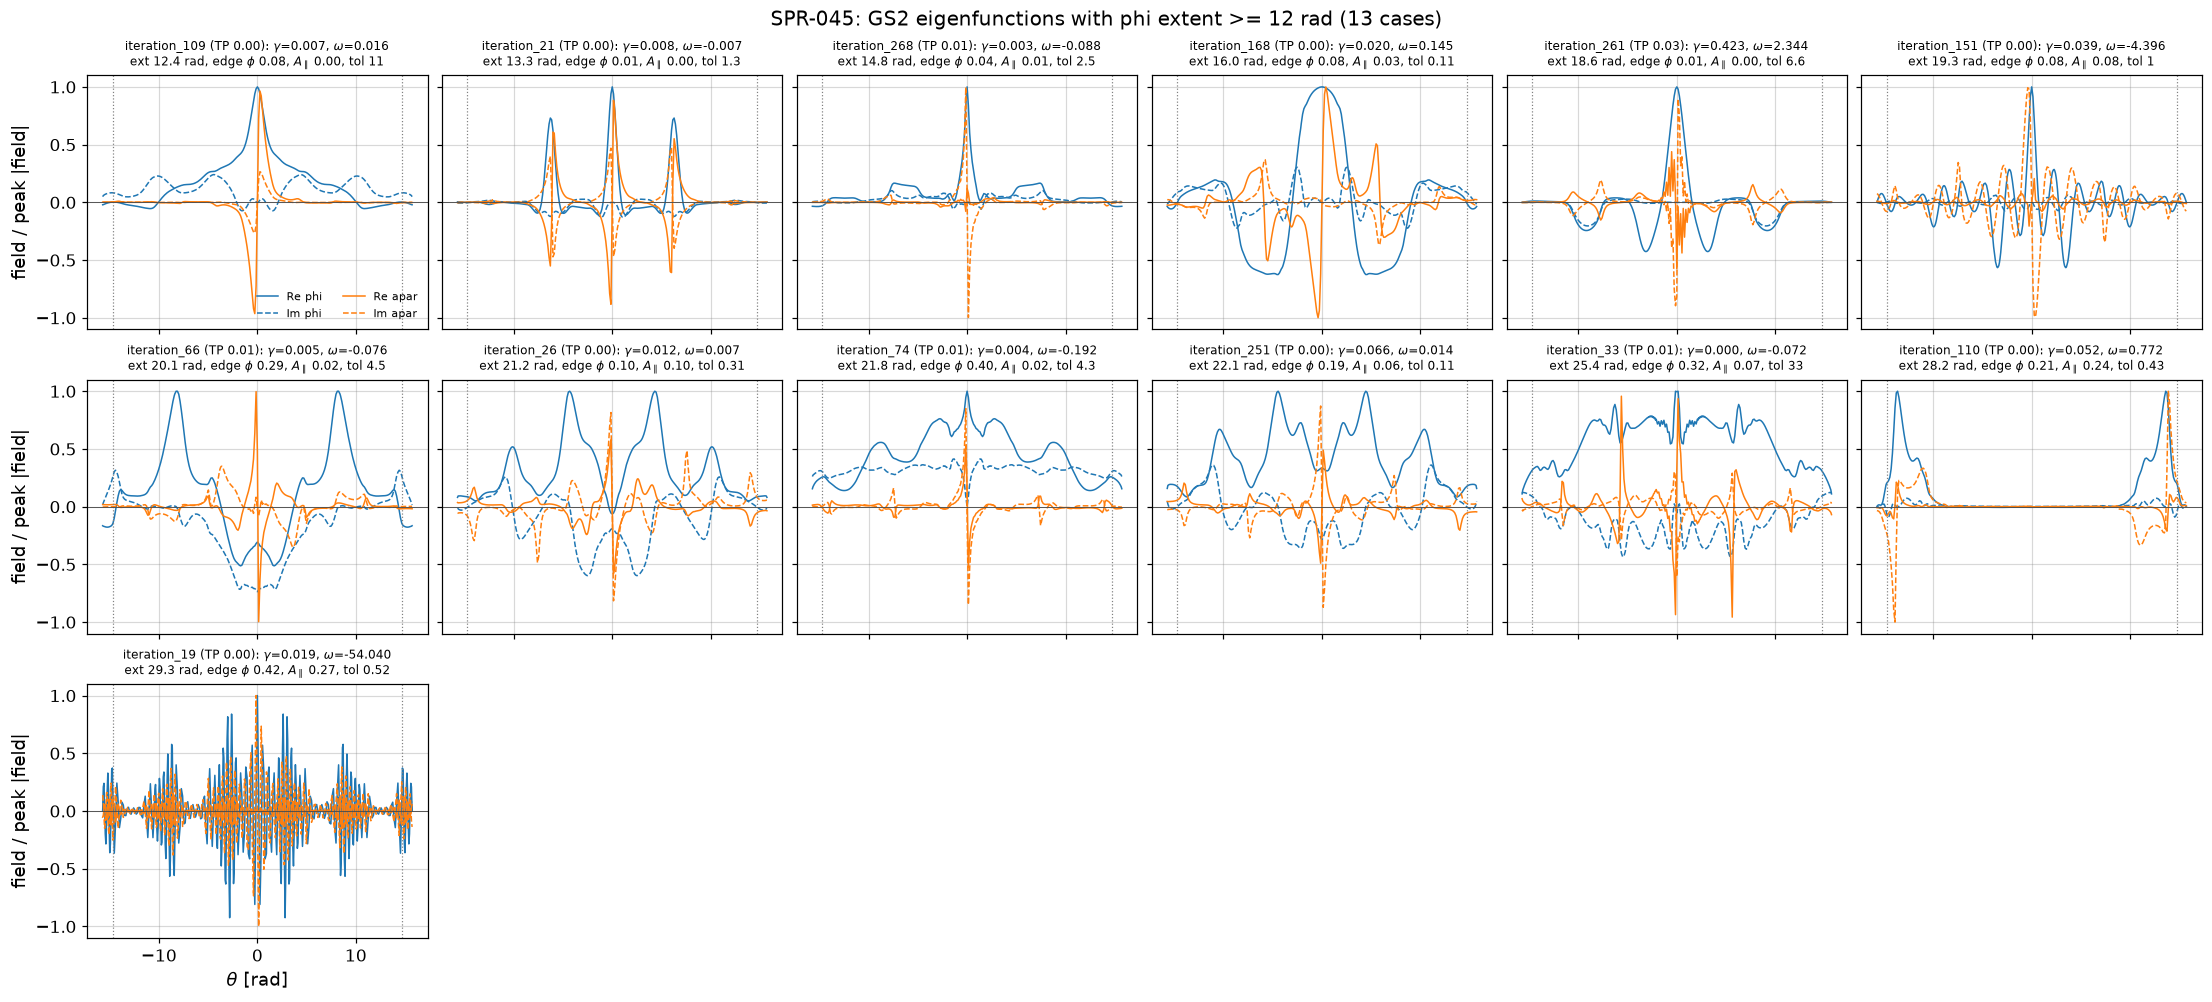

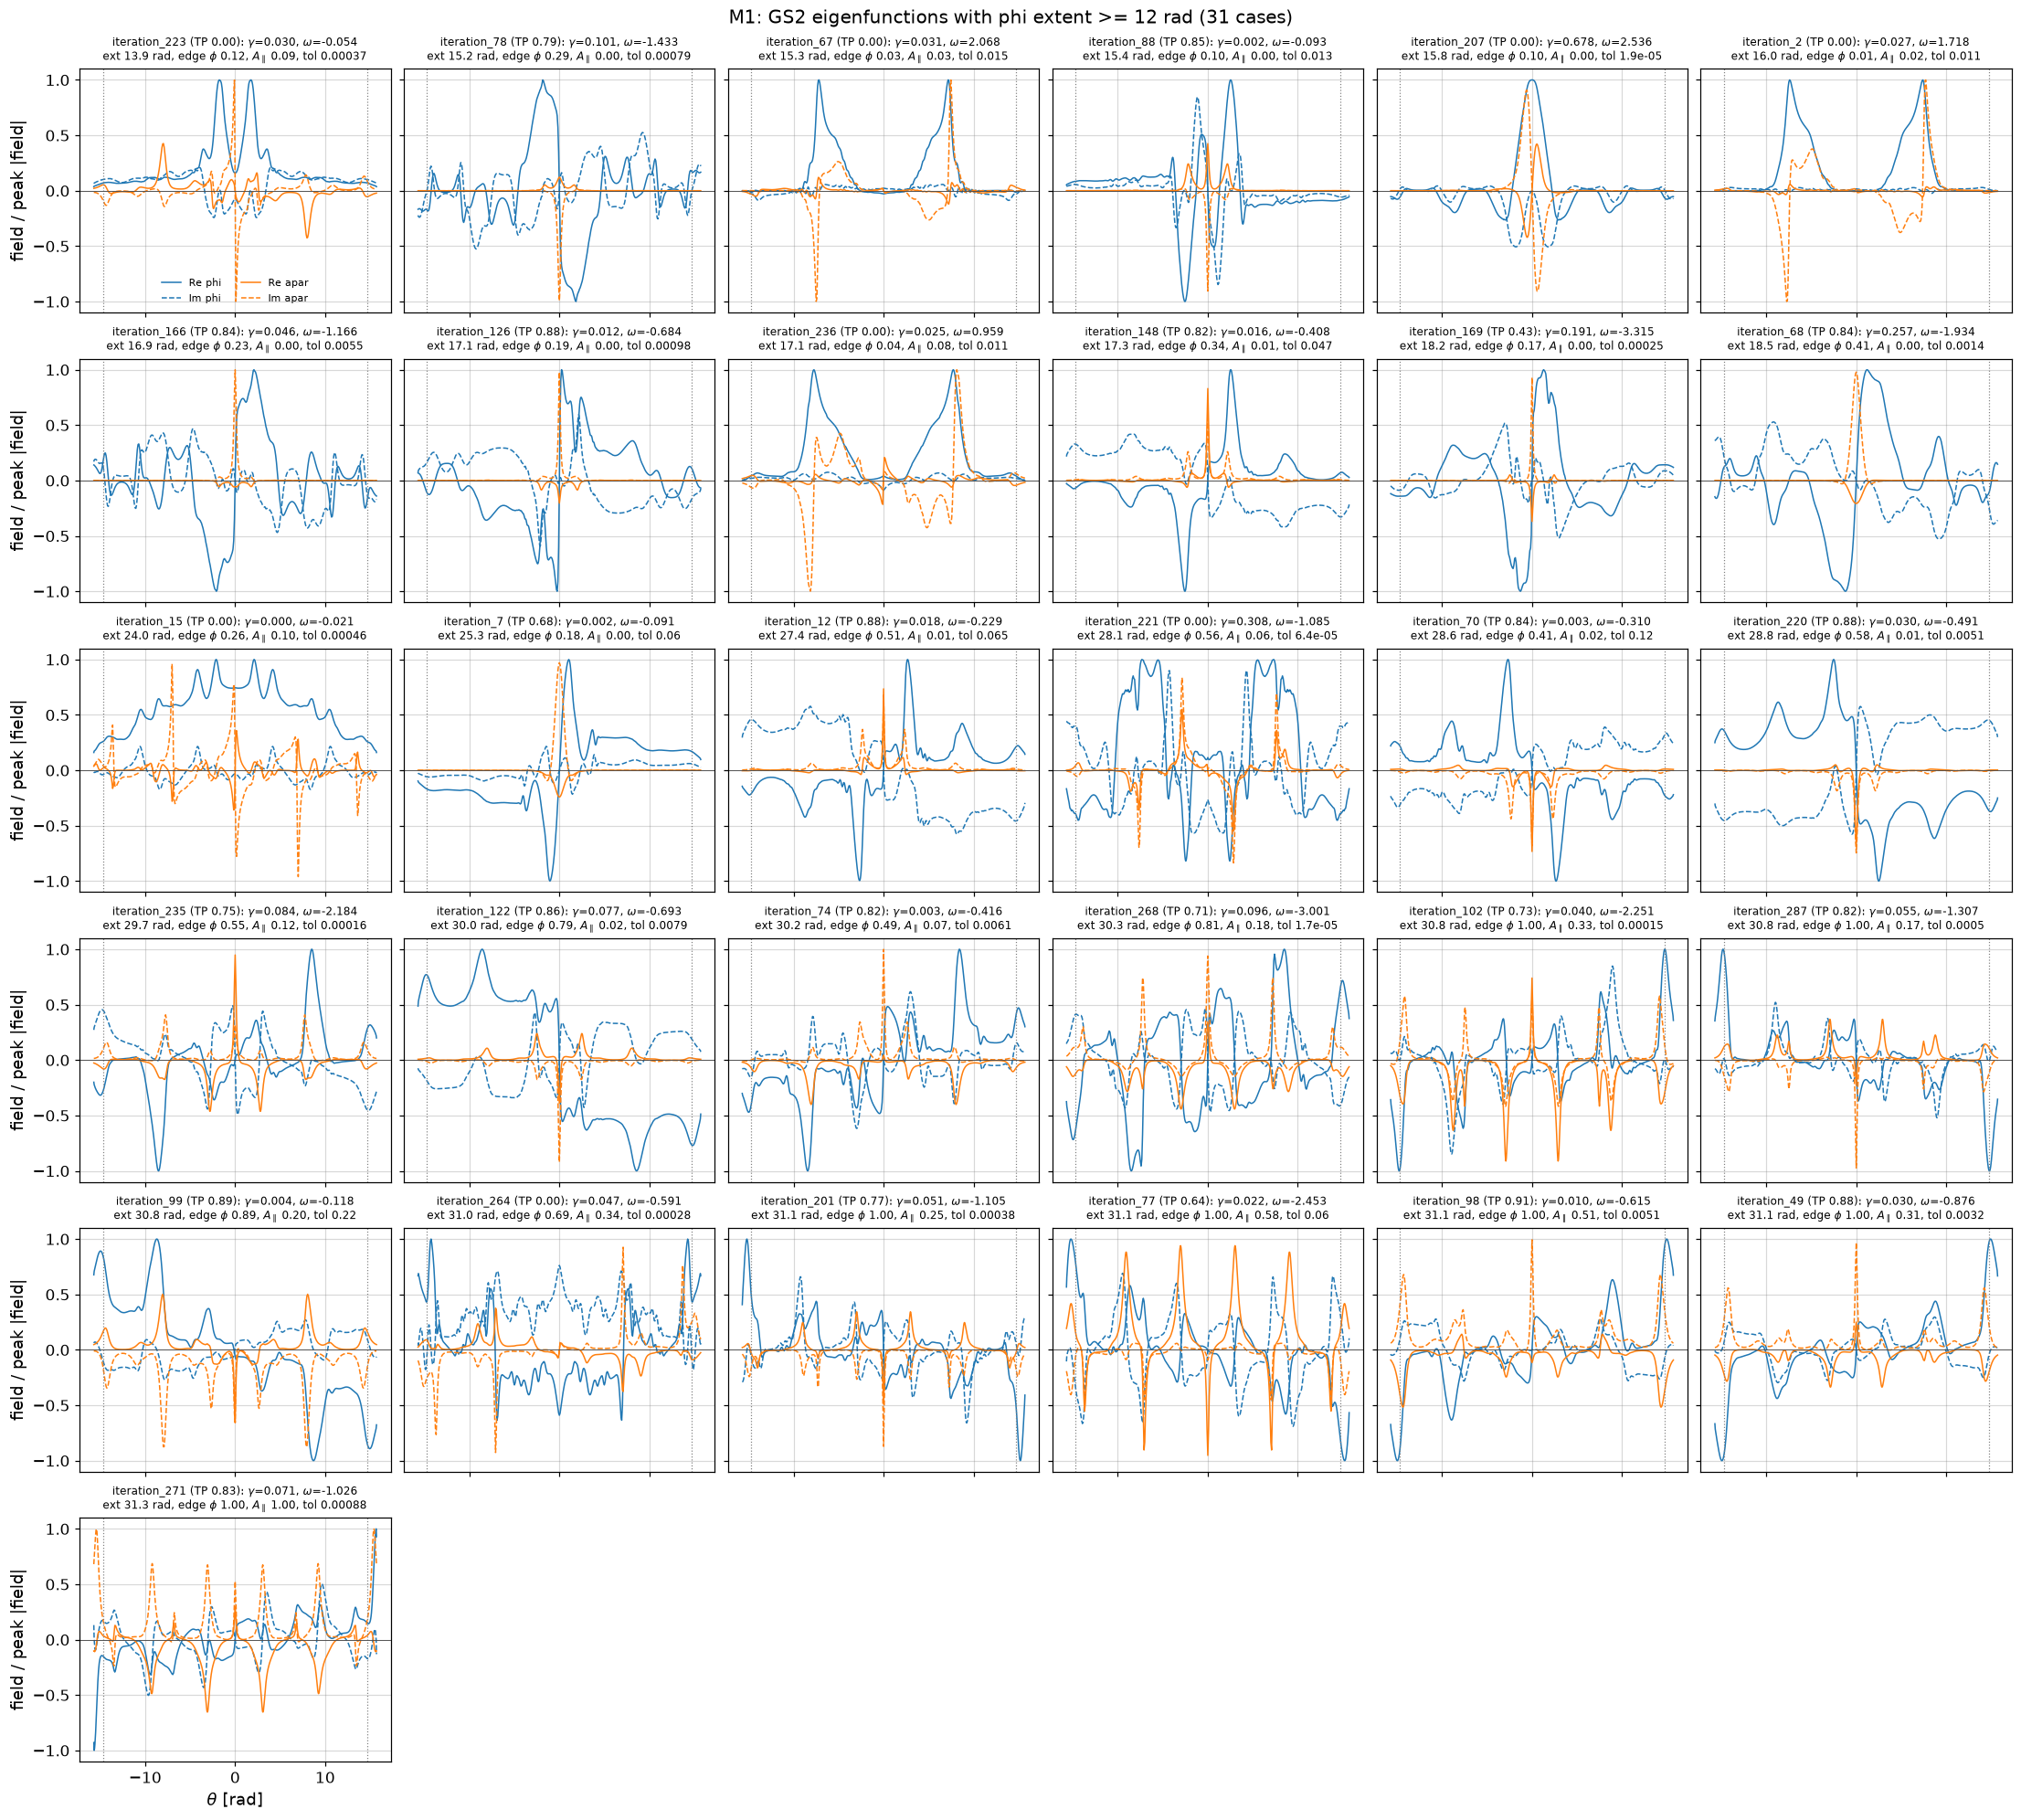

In [ ]:
fig14 = {}
for db in cases:
    ref = gs2[db].data
    ext_cases = gs2_diag[(gs2_diag.db == db) & (gs2_diag.group == "extended")].sort_values("ext_phi")
    ncols = 6
    nrows = int(np.ceil(len(ext_cases) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(20, 3 * nrows), sharex=True, sharey=True, squeeze=False)
    theta_edge = np.abs(ref.theta.values).max()
    for ax, (_, c) in zip(axes.flat, ext_cases.iterrows()):
        s = int(np.where(ref.sample_name.values == c["name"])[0][0])
        e = {f: mag(ref.eigenfunctions.sel(field=f).isel(sample=s)) for f in ("phi", "apar")}
        rotation = np.exp(-1j * np.angle(e["phi"][np.abs(e["phi"]).argmax()]))   # phi peak real and positive; same rotation for apar
        for f, colour in (("phi", "C0"), ("apar", "C1")):
            z = e[f] * rotation / np.abs(e[f]).max()
            ax.plot(ref.theta, z.real, color=colour, ls="-", marker="", lw=1, label=f"Re {f}")
            ax.plot(ref.theta, z.imag, color=colour, ls="--", marker="", lw=1, label=f"Im {f}")
        for x in (-theta_edge + edge_window, theta_edge - edge_window):
            ax.axvline(x, color="0.5", ls=":", lw=0.8, marker="")
        ax.axhline(0, color="0.3", lw=0.6, marker="")
        ax.set(ylim=(-1.1, 1.1),
               title=f"{c['name']} (TP {c.tearing_parameter:.2f}): $\\gamma$={c.gamma:.3f}, $\\omega$={c.omega:.3f}\n"
                     f"ext {c.ext_phi:.1f} rad, edge $\\phi$ {c.edge_phi:.2f}, $A_\\parallel$ {c.edge_apar:.2f}, tol {c.gamma_tol:.2g}")
        ax.title.set_fontsize(8)
    for ax in axes.flat[len(ext_cases):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set(xlabel=r"$\theta$ [rad]")
    for ax in axes[:, 0]:
        ax.set(ylabel="field / peak |field|")
    axes[0, 0].legend(fontsize=7, ncols=2)
    fig.suptitle(f"{db}: GS2 eigenfunctions with phi extent >= {extended_threshold:g} rad ({len(ext_cases)} cases)")
    fig14[db] = fig
plt.show()

In [ ]:
for db, fig in fig14.items():
    fig.savefig(ROOT / "Plots" / analysis_name / f"gs2_phi_apar_eigenfunction_vs_theta_{db}.png")

Fig 15: pyro tearing parameter vs GS2 phi extent, coloured by the inline even-fraction parity label; dashed:
`tearing_threshold`, dotted: `extended_threshold`.